# DME Circuit
Note: DME($\pi/2$) is equivalent to a SWAP gate.

## Circuit draw
Draw DME($\phi$) circuit. Note that the phase of the ZZ gate is $\phi/2$, and the duration to evolve the ZZ can be found by $\phi/2 = t\omega$.

<>:8: SyntaxWarning: invalid escape sequence '\p'
<>:8: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Admin\AppData\Local\Temp\ipykernel_34160\3439873749.py:8: SyntaxWarning: invalid escape sequence '\p'
  phi = Parameter('\phi/2')


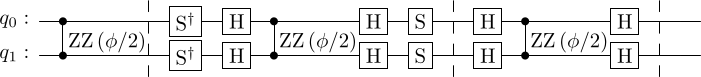

In [1]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.circuit.library import RZZGate
from qiskit.circuit import Gate

# Create a parameter for the angle
phi = Parameter('t')
phi = Parameter('\phi/2')

# Create a quantum circuit with two qubits
qc = QuantumCircuit(2)

# ZZ gate with the symbolic parameter t
qc.append(RZZGate(phi), [0, 1])
qc.barrier()

# YY gate
qc.sdg(0)
qc.sdg(1)
qc.h(0)
qc.h(1)
qc.append(RZZGate(phi), [0, 1])
qc.h(0)
qc.h(1)
qc.s(0)
qc.s(1)

qc.barrier()

# XX gate
qc.h(0)
qc.h(1)
qc.append(RZZGate(phi), [0, 1])
qc.h(0)
qc.h(1)

qc.barrier()

# Draw the circuit with the parameter t
qc.draw(output='latex', style="bw")


## Check using the dme function
The dme function can be accessed by importing `from functions.dme import *`. It takes numpy arrays for data and instruction qubit, phase of evolution, and number of iteration, apply the channel, and output the data density matrix.

In the following code, the phase $\phi$ of the DME evolution is set to be $\pi/2$. As noted above, this is a SWAP gate. 
The data and instruction state are randomly created. DME is performed on the two qubits, and we expect the data qubit to be swapped with the instruction qubit.

In [2]:
import sys
sys.path.append('..')
from functions.dme import *
import numpy as np

phi = np.pi/2
M = 1

psi0 = np.random.rand(2) + 1j * np.random.rand(2)
psi0 /= np.linalg.norm(psi0)
psi0 = psi0[np.newaxis].T
data = psi0@psi0.conj().T
print(f'Initial data qubit:\n{data}')

psi0 = np.random.rand(2) + 1j * np.random.rand(2)
psi0 /= np.linalg.norm(psi0)
psi0 = psi0[np.newaxis].T
instruction = psi0@psi0.conj().T
print(f'Initial instruction qubit:\n{instruction}')

print(f'Data qubit after DME:\n{dme_channel(data,instruction,phi,M)[0]}')

Initial data qubit:
[[0.51190298+0.j         0.36651365+0.33989125j]
 [0.36651365-0.33989125j 0.48809702+0.j        ]]
Initial instruction qubit:
[[0.29937376+0.j         0.24031352-0.38986988j]
 [0.24031352+0.38986988j 0.70062624+0.j        ]]
Data qubit after DME:
[[0.29937376+0.j         0.24031352-0.38986988j]
 [0.24031352+0.38986988j 0.70062624+0.j        ]]


## Process tomography
DME is decomposed into Heisenberg (XX, YY, ZZ) as per the circuit drawn above. We perform QPT on the dme_heisenberg channel for different duration.

In [3]:
import numpy as np
from scipy.linalg import expm
from functions.plot_process_matrix import plot_process_matrix
from qutip.tomography import qpt
from qutip import gates, spre,spost,qeye,sigmax,sigmay,sigmaz,tensor,Qobj
import matplotlib.pyplot as plt

I = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]])
S = np.array([[1, 0], [0, 1j]])
S_dagger = S.conj().T

II = np.kron(I, I)
XX = np.kron(X, X)
YY = np.kron(Y, Y)
ZZ = np.kron(Z, Z)

def dme_heisenberg(phi):
    ZZ_phi = expm(-1j*phi/2*ZZ)
    YY_phi = np.kron(S_dagger,I) @ np.kron(H,I) @ np.kron(I,S_dagger) @ np.kron(I,H) @ expm(-1j*phi/2*ZZ) @ np.kron(H,I) @ np.kron(S,I) @ np.kron(I,H) @ np.kron(I,S)
    XX_phi = np.kron(H,I) @ np.kron(I,H) @ expm(-1j*phi/2*ZZ) @ np.kron(H,I) @ np.kron(I,H)
    return (ZZ_phi @ YY_phi @ XX_phi)

pauli_labels = ["I", "X", "Y", "Z"]
pauli_labels_2q = ['II', 'IX', 'IY', 'IZ',
 'XI', 'XX', 'XY', 'XZ',
 'YI', 'YX', 'YY', 'YZ',
 'ZI', 'ZX', 'ZY', 'ZZ']

### 1. Sanity check: ZZ
First, we check the QPT for the ZZ interaction. I use qutip to do the QPT.

The first case: $\phi = \pi$

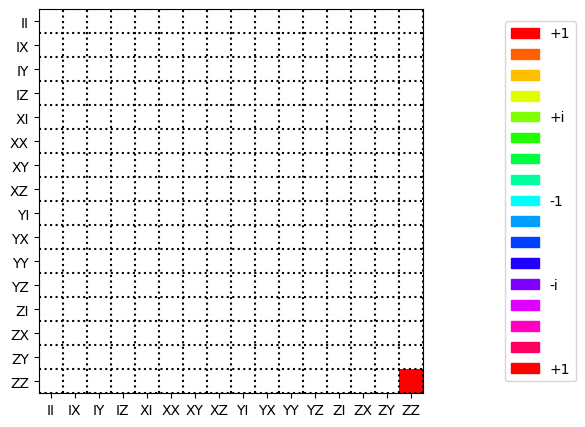

In [11]:
def RZZ(phi):
    return expm(-1j*phi*ZZ)

U_psi = Qobj(RZZ(np.pi/2))
U_rho = spre(U_psi) * spost(U_psi.dag())
op_basis = [[qeye(2), sigmax(), sigmay(), sigmaz()]] * 2

chi = qpt(U_rho, op_basis)
plot_process_matrix(np.asarray(chi), pauli_labels_2q)

Next, we look at a random phase $\phi=0.5$

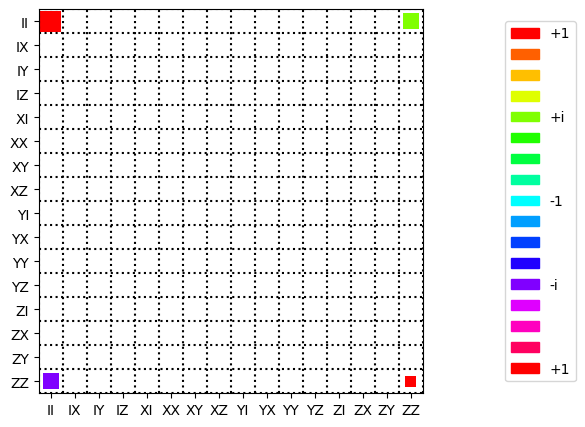

In [12]:
U_psi = Qobj(RZZ(0.5))
U_rho = spre(U_psi) * spost(U_psi.dag())
op_basis = [[qeye(2), sigmax(), sigmay(), sigmaz()]] * 2

chi = qpt(U_rho, op_basis)
plot_process_matrix(np.asarray(chi), pauli_labels_2q)

### 2. DME QPT

Next, we check that DME($\pi/2$) is indeed the SWAP gate, both by looking at the matrices and the QPT. 

In [6]:
np.round(dme_heisenberg(np.pi/2),2)

array([[ 0.71-0.71j,  0.  -0.j  ,  0.  -0.j  ,  0.  +0.j  ],
       [ 0.  -0.j  ,  0.  +0.j  ,  0.71-0.71j,  0.  -0.j  ],
       [ 0.  -0.j  ,  0.71-0.71j,  0.  +0.j  , -0.  +0.j  ],
       [ 0.  +0.j  , -0.  +0.j  ,  0.  -0.j  ,  0.71-0.71j]])

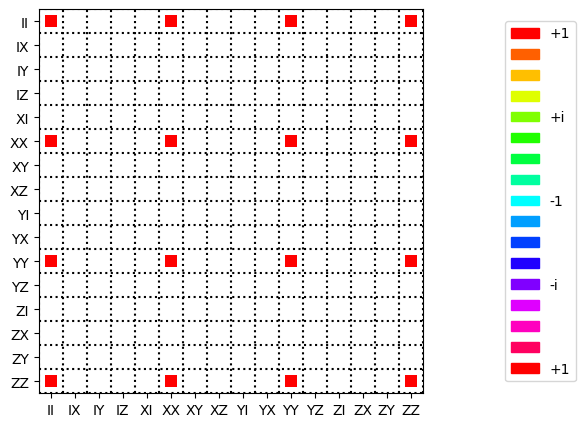

In [7]:
U_psi = Qobj(dme_heisenberg(np.pi/2))
# #Uncomment the following line to see that dme(pi/2) is in fact swap gate
# U_psi = gates.swap()

U_rho = spre(U_psi) * spost(U_psi.dag())
op_basis = [[qeye(2), sigmax(), sigmay(), sigmaz()]] * 2

chi = qpt(U_rho, op_basis)
plot_process_matrix(np.asarray(chi), pauli_labels_2q)

Next, we modify the phase $\phi$ of DME here to find the corresponding QPT:

In [8]:
# Modify this
phi = np.pi/4

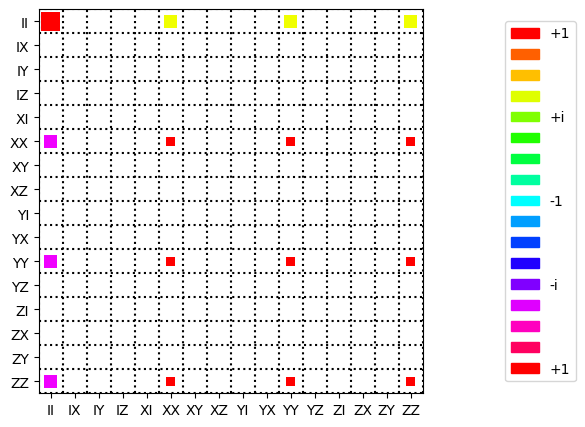

In [9]:
U_psi = Qobj(dme_heisenberg(phi))
U_rho = spre(U_psi) * spost(U_psi.dag())
op_basis = [[qeye(2), sigmax(), sigmay(), sigmaz()]] * 2
chi = qpt(U_rho, op_basis)
plot_process_matrix(np.asarray(chi), pauli_labels_2q)

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from qutip import Qobj, spre, spost, qeye, sigmax, sigmay, sigmaz, qpt
# --- Pauli basis for QPT --- #
pauli_basis = [qeye(2), sigmax(), sigmay(), sigmaz()]
op_basis = [pauli_basis, pauli_basis]
pauli_labels_2q = ['II', 'IX', 'IY', 'IZ',
                   'XI', 'XX', 'XY', 'XZ',
                   'YI', 'YX', 'YY', 'YZ',
                   'ZI', 'ZX', 'ZY', 'ZZ']
# --- Define PTM labels --- #
ptm_labels = pauli_labels_2q
# --- Ideal ZZ unitary definition --- #
def zz_unitary(theta):
    return np.diag([
        -np.exp(-1j * theta / 2),
        np.exp(1j * theta / 2),
        np.exp(1j * theta / 2),
        -np.exp(-1j * theta / 2)
    ])
# --- Convert unitary to PTM --- #
def unitary_to_ptm(U: Qobj):
    paulis = [qeye(2), sigmax(), sigmay(), sigmaz()]
    basis = [Qobj(np.kron(p1.full(), p2.full())) for p1 in paulis for p2 in paulis]
    T = np.zeros((16, 16), dtype=np.complex128)
    for i, Pi in enumerate(basis):
        rho_out = U * Pi * U.dag()
        for j, Pj in enumerate(basis):
            T[j, i] = (Pj.dag() * rho_out).tr() / 2
    return T 


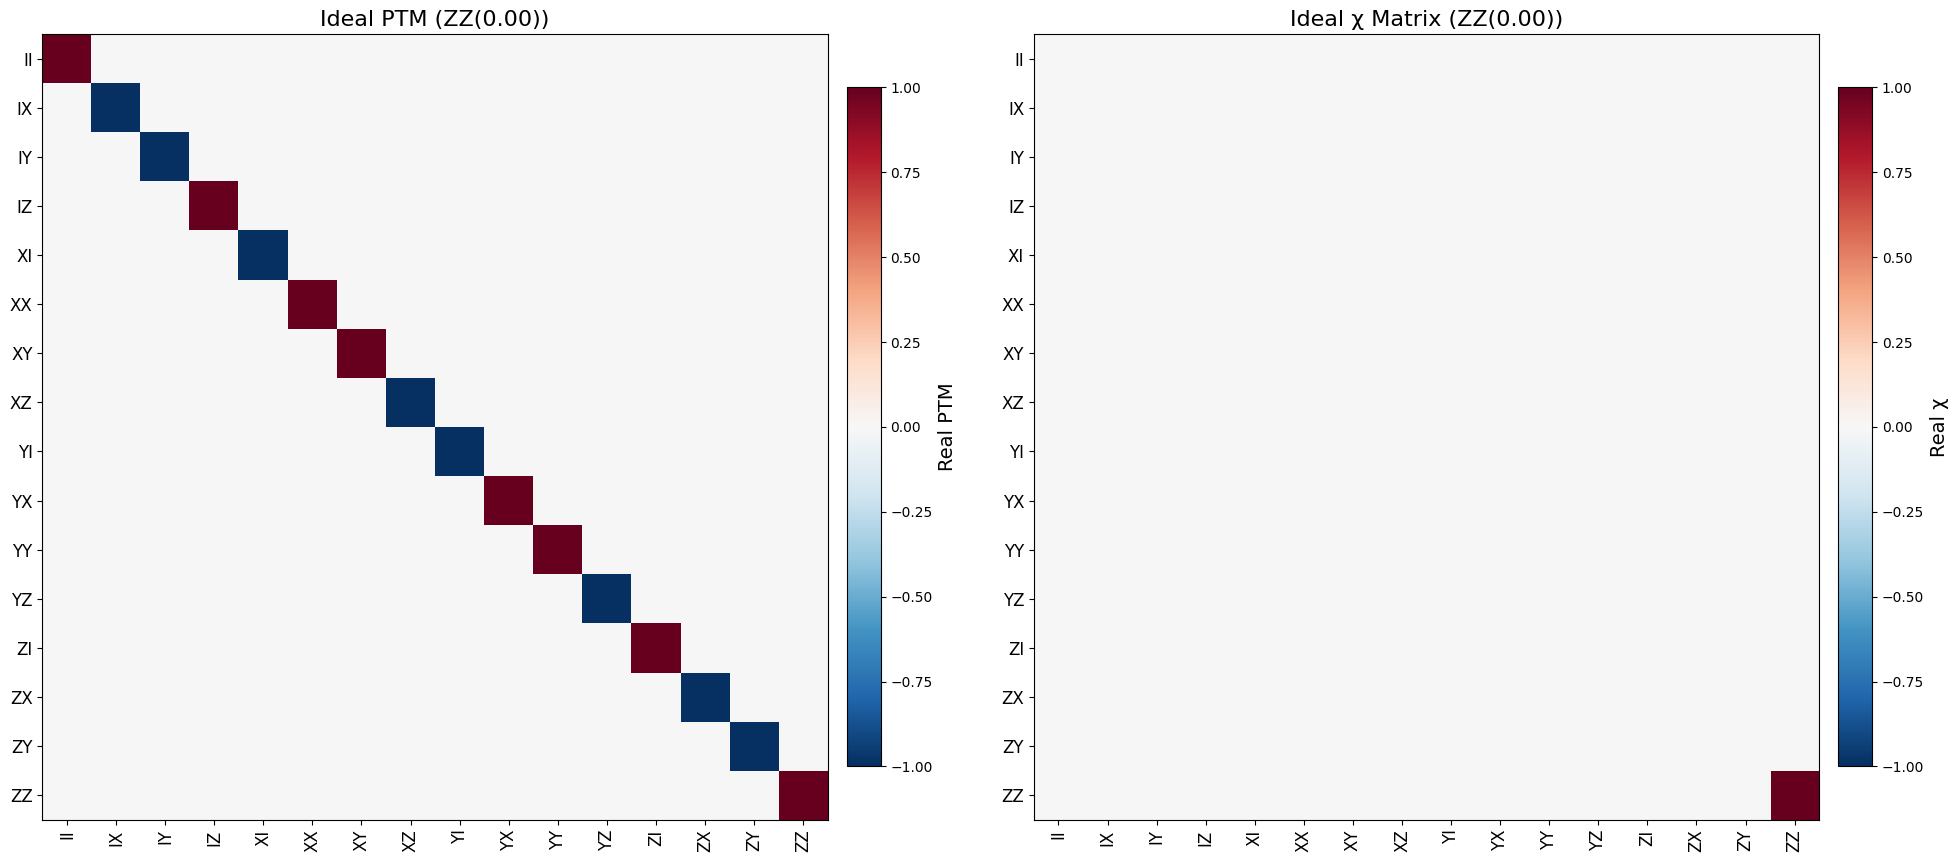

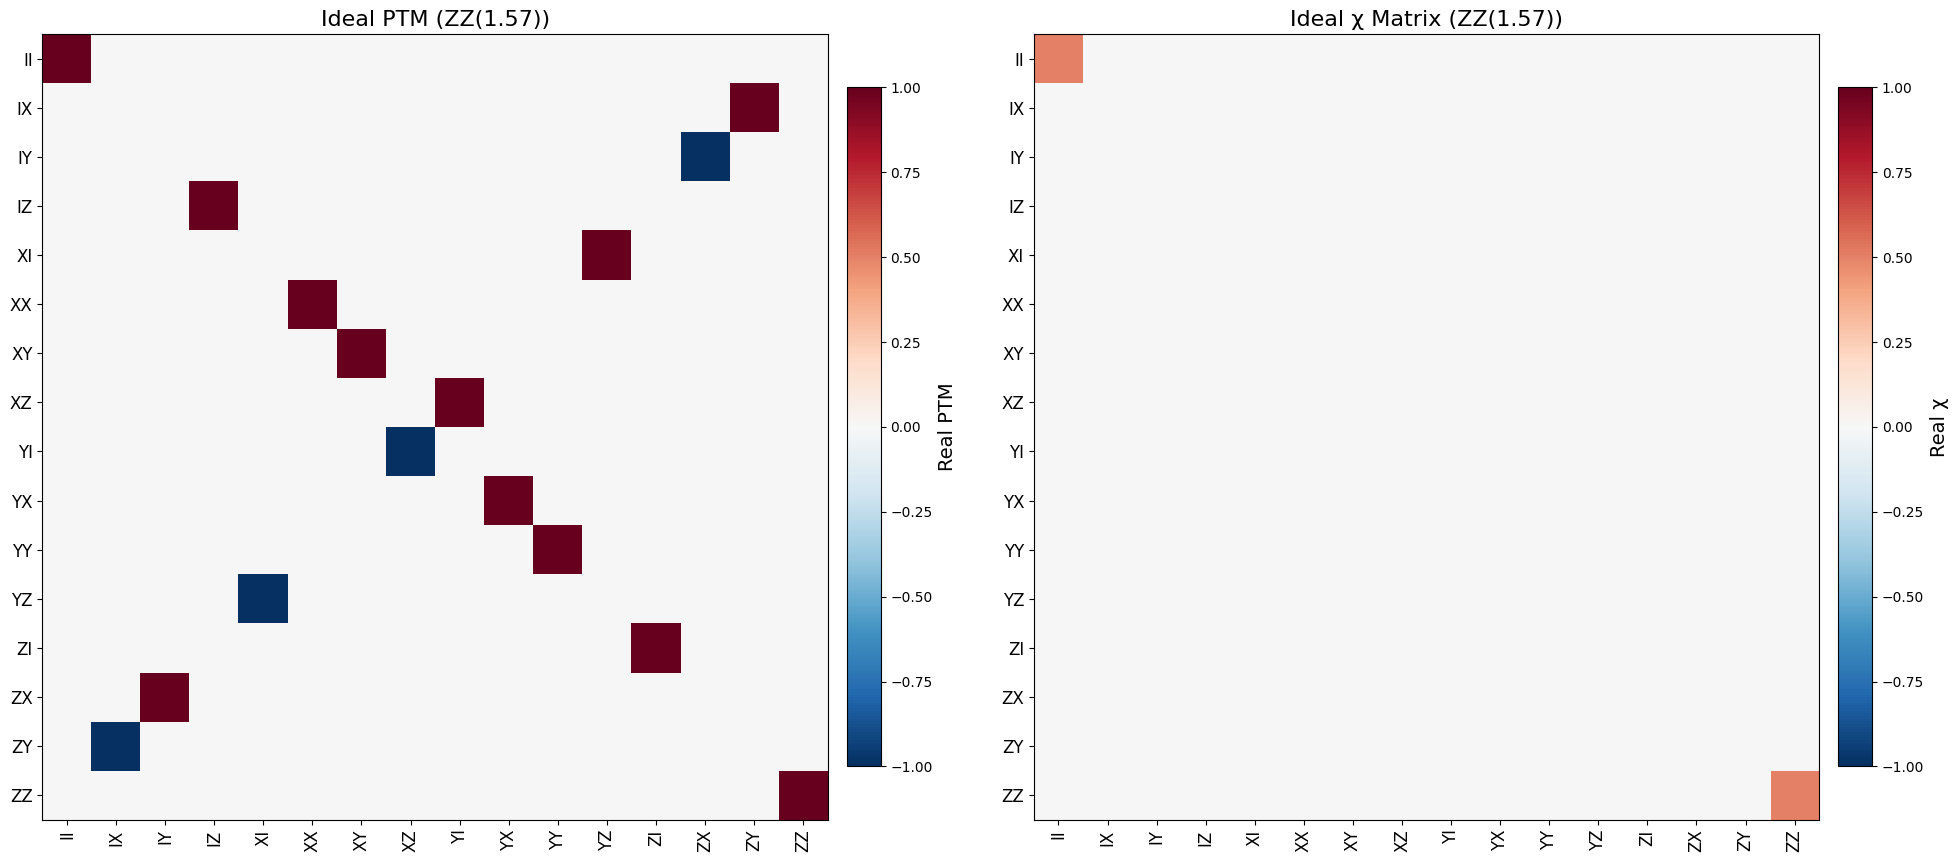

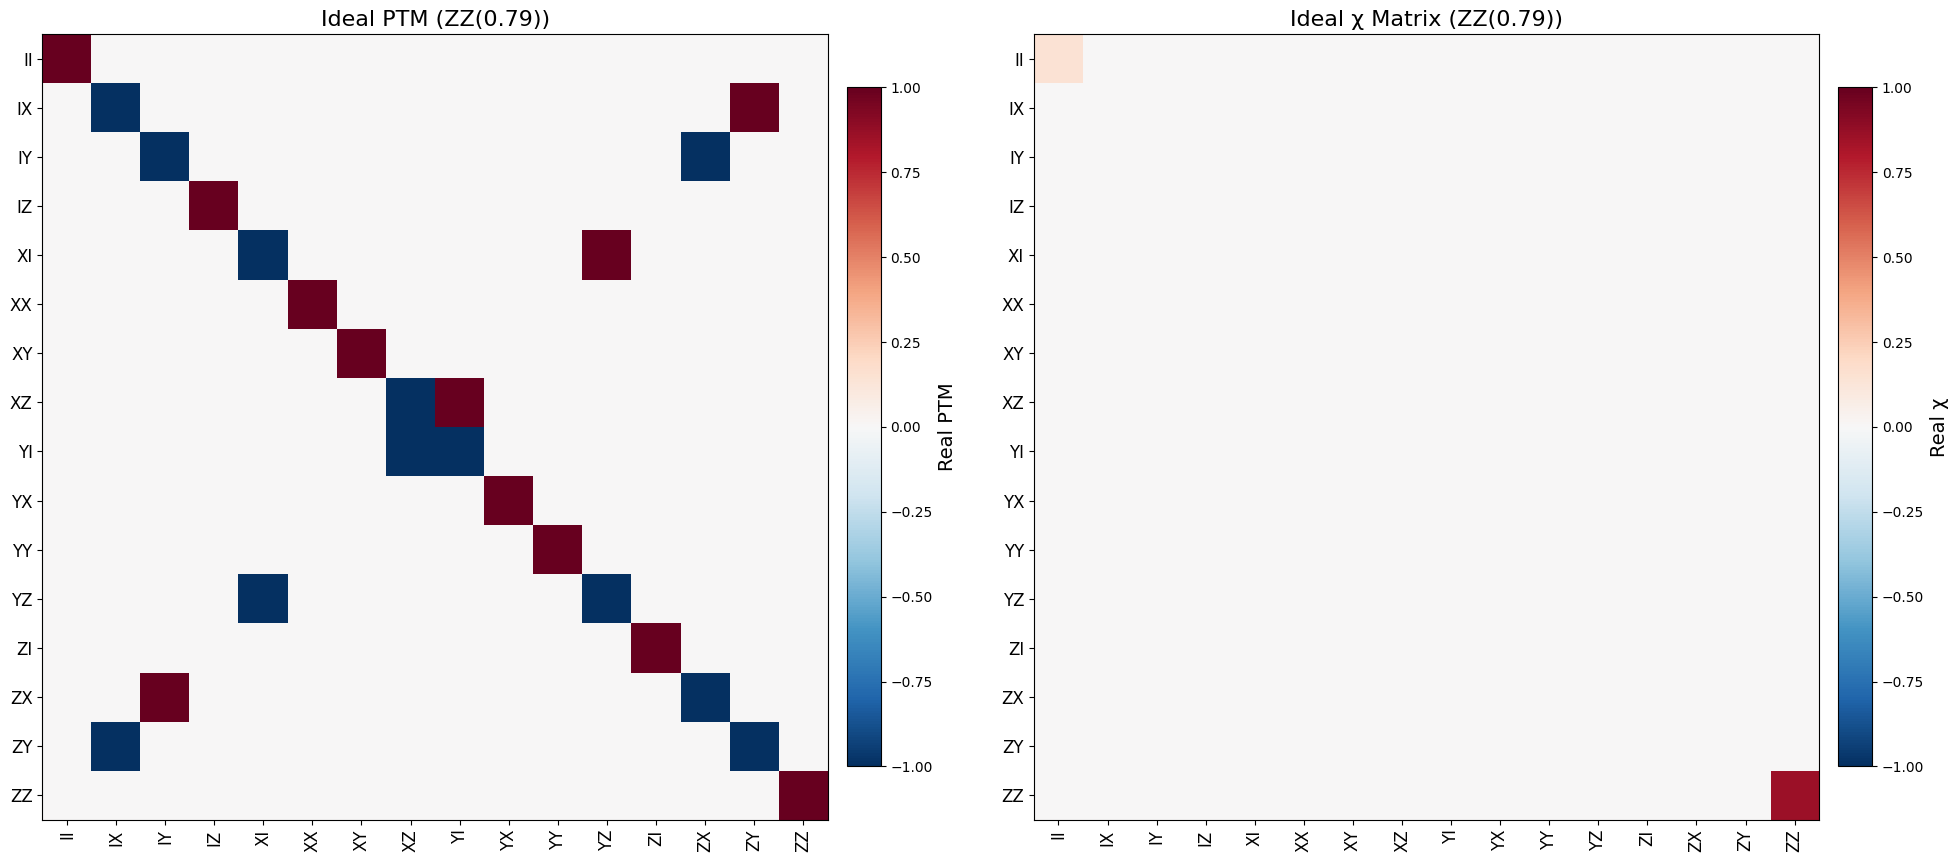

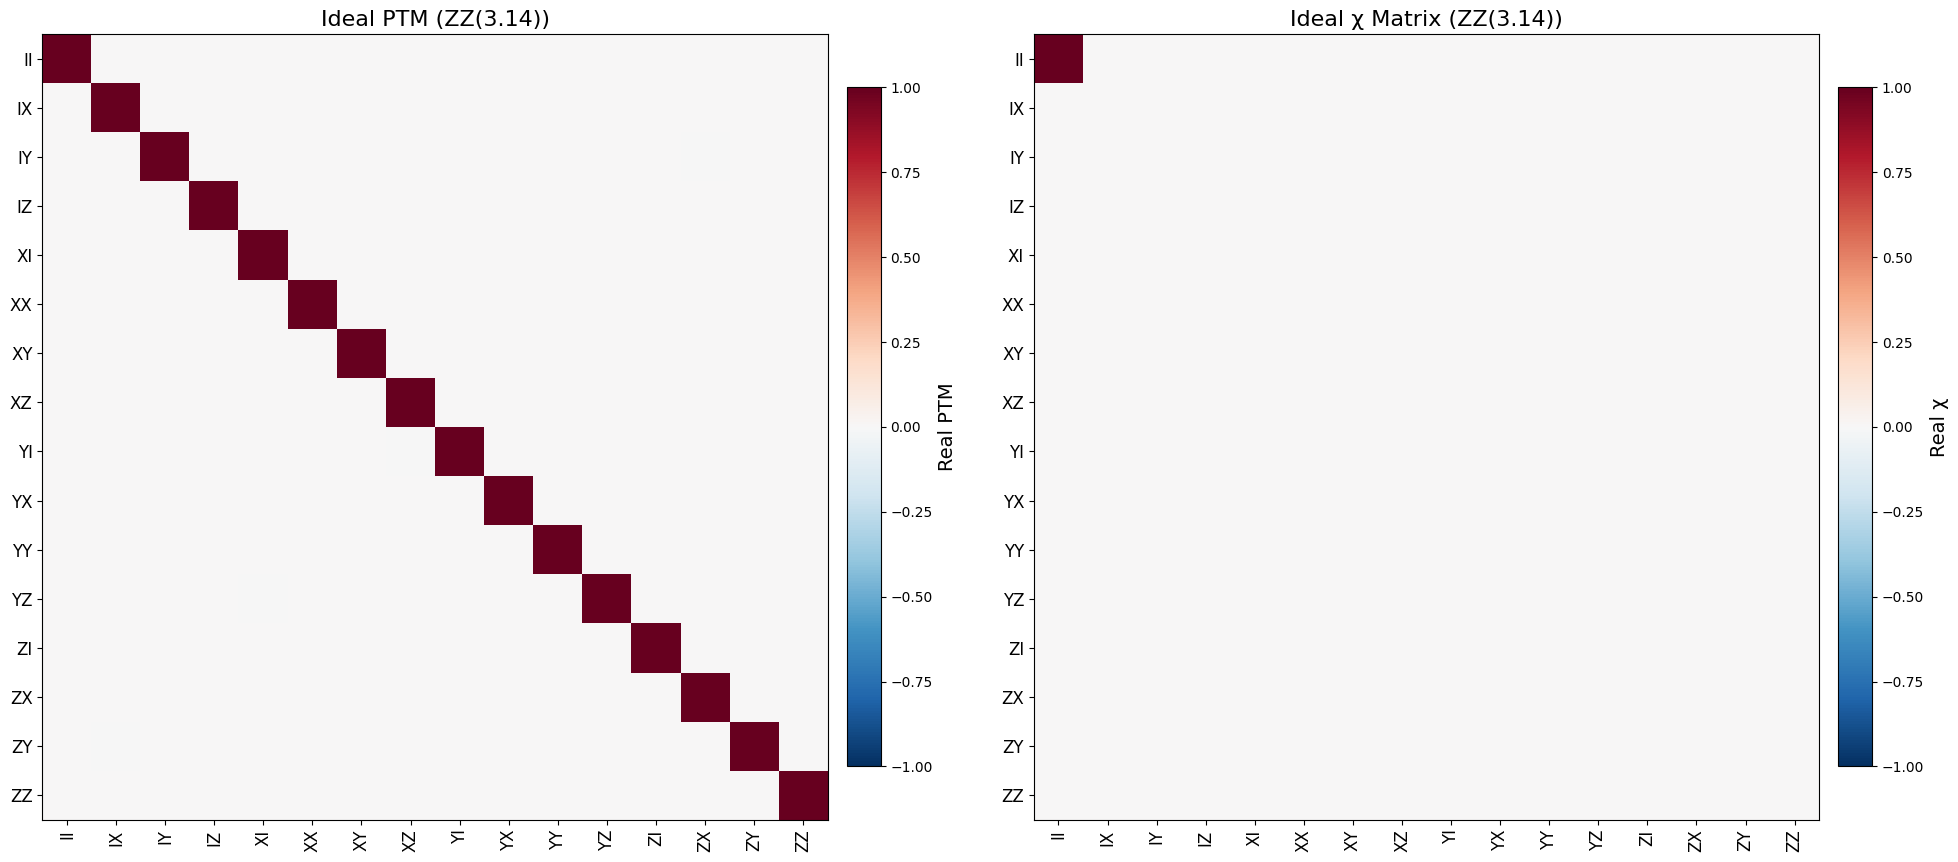

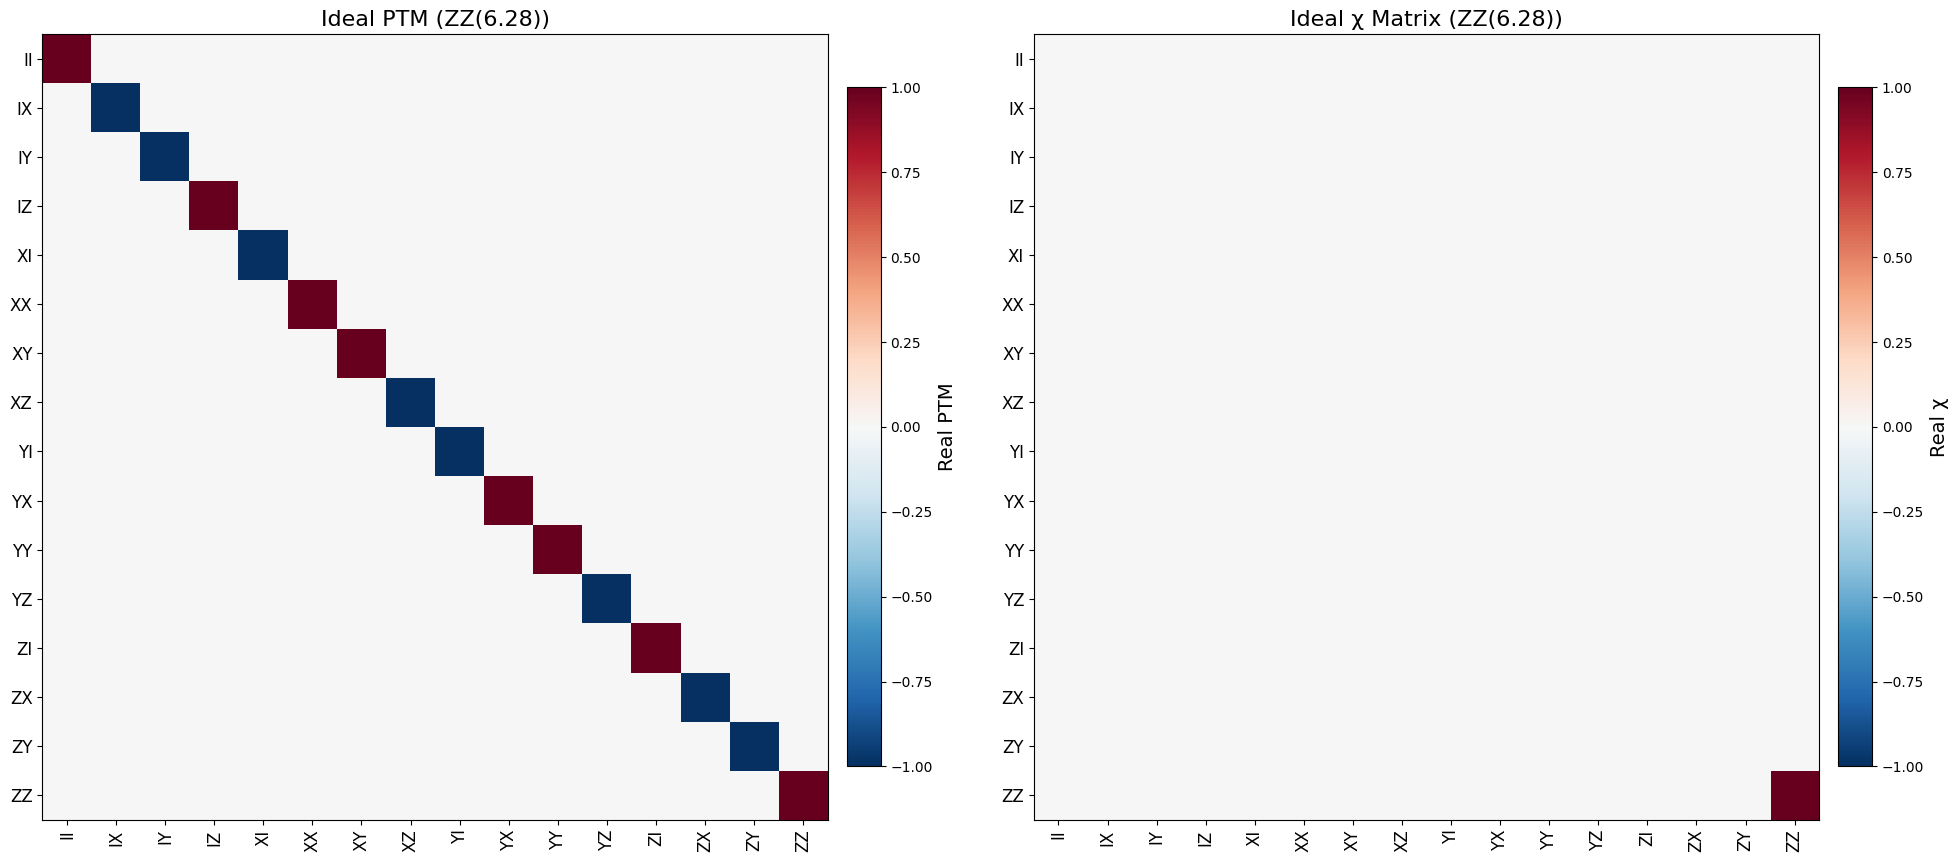

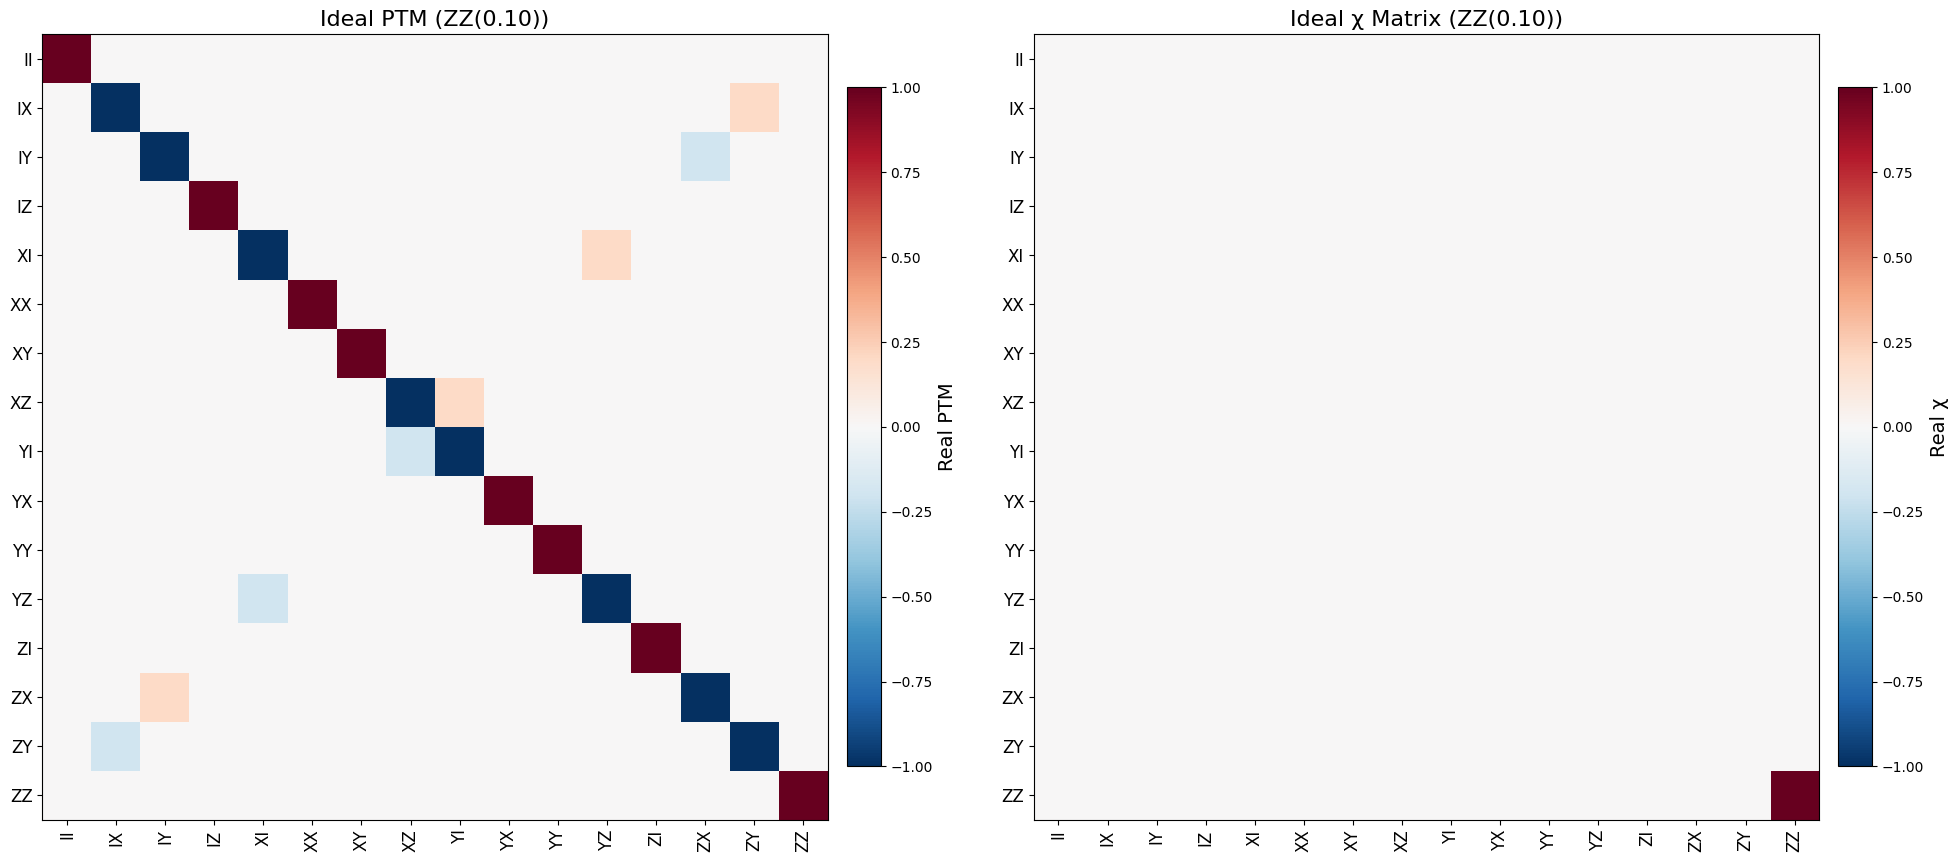

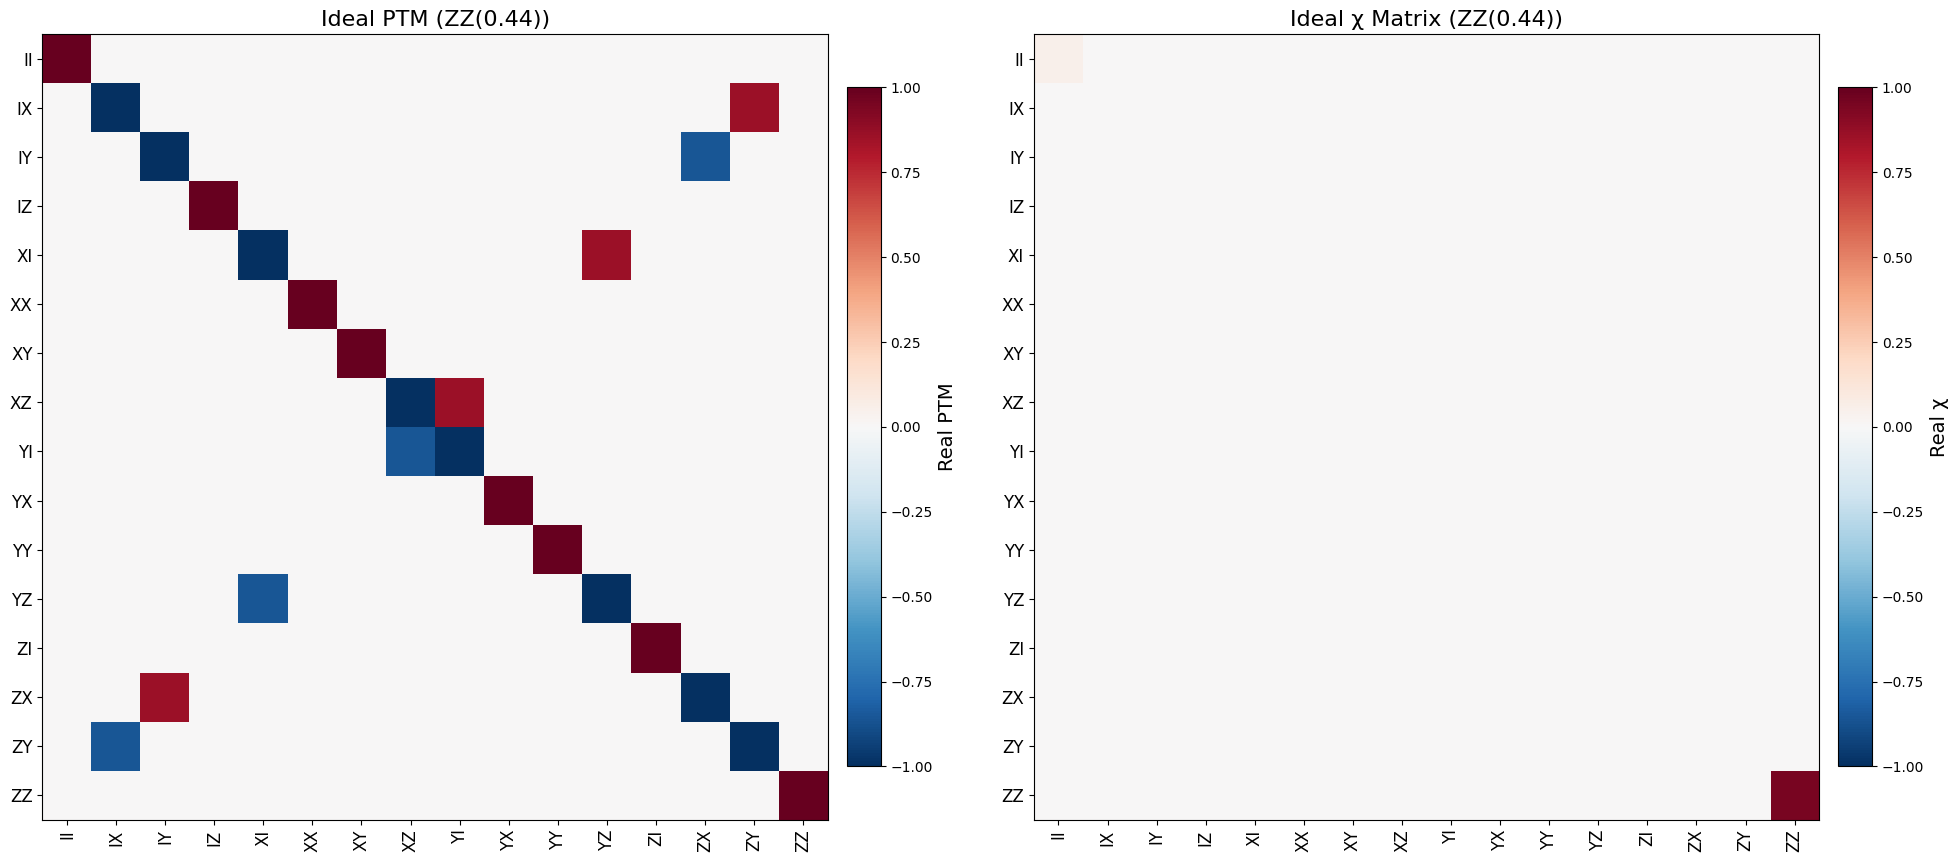

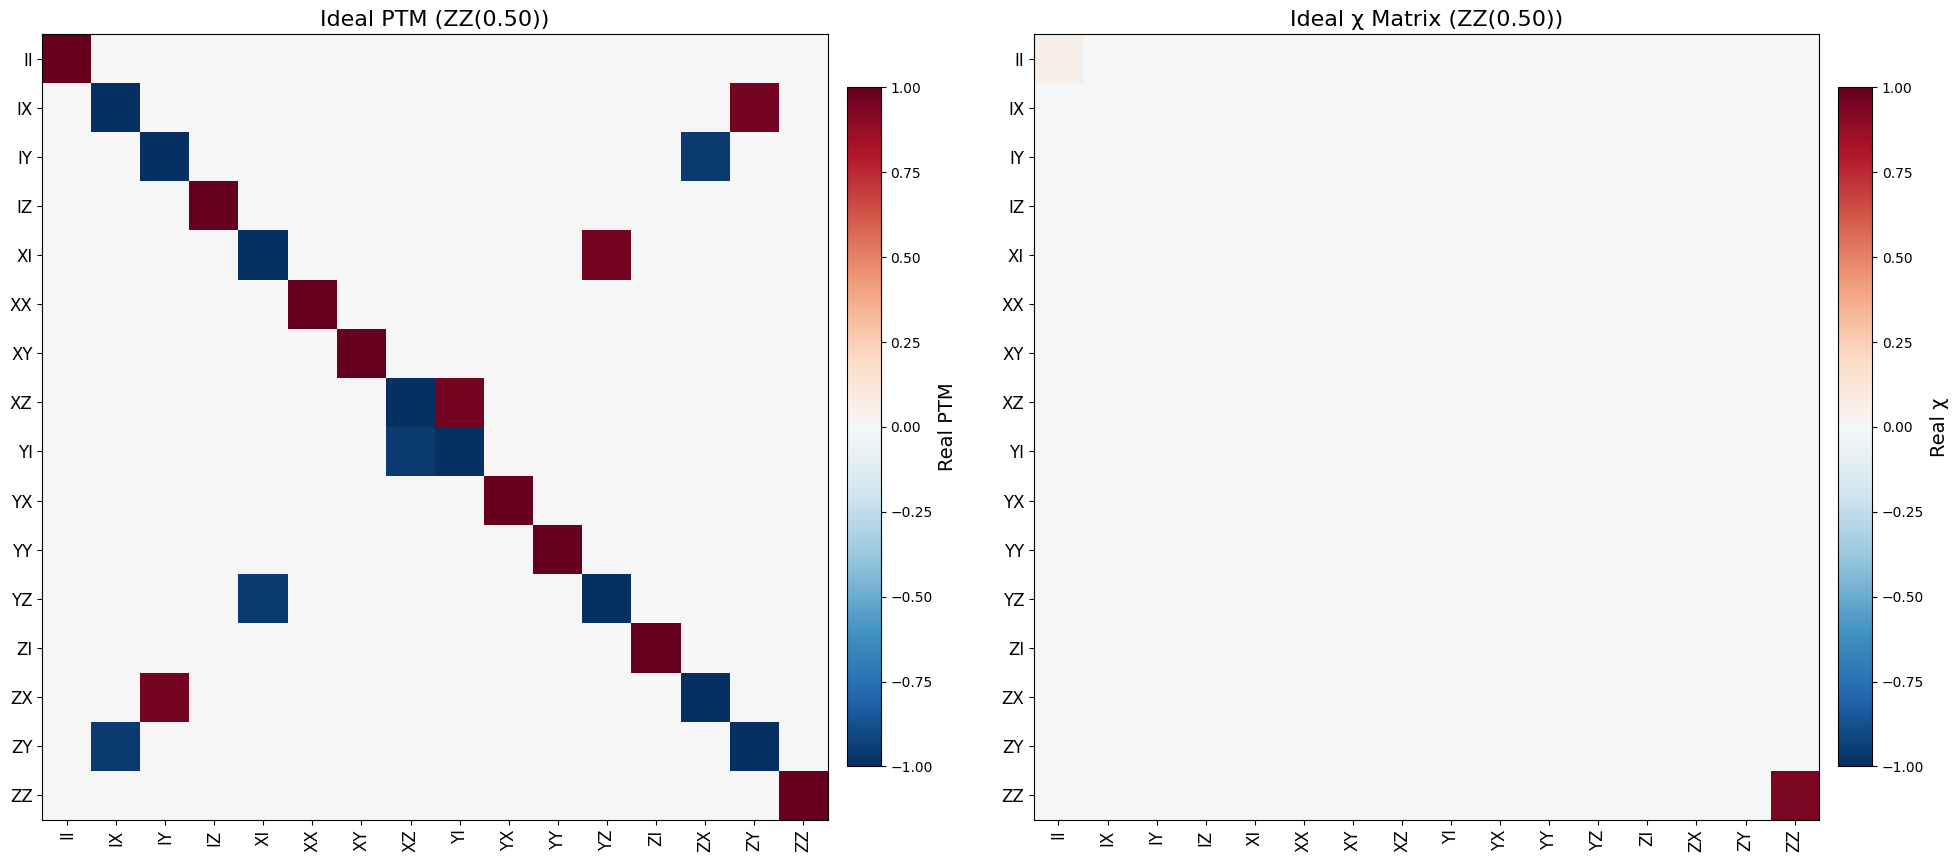

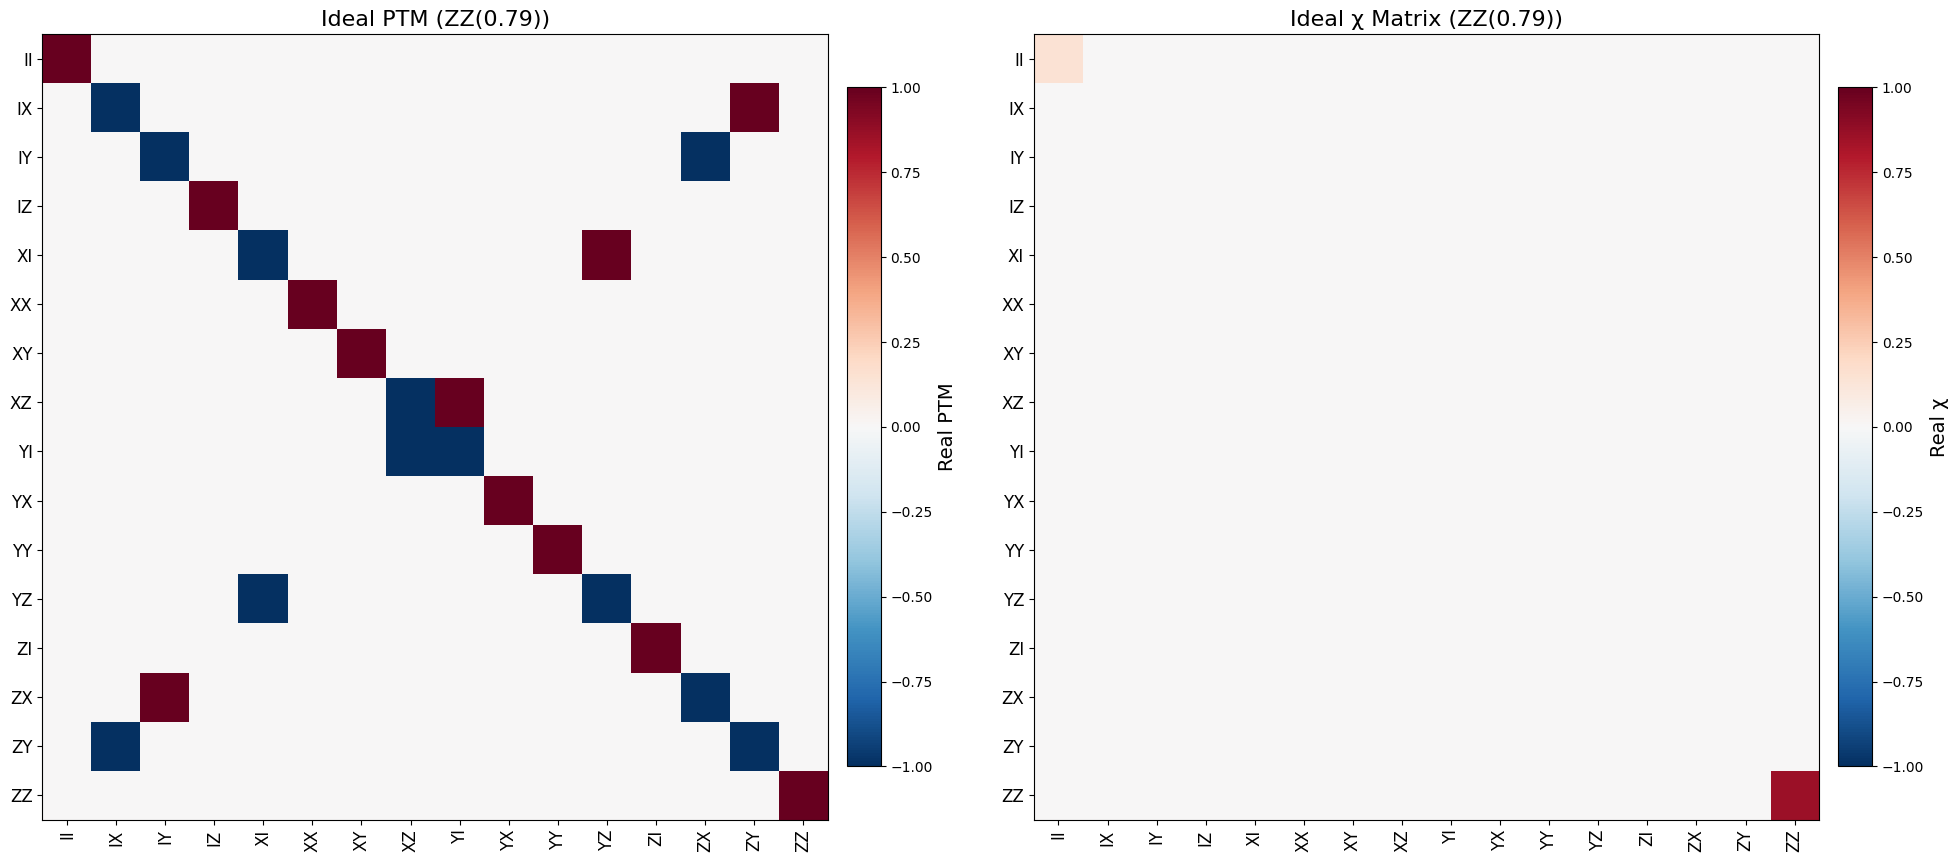

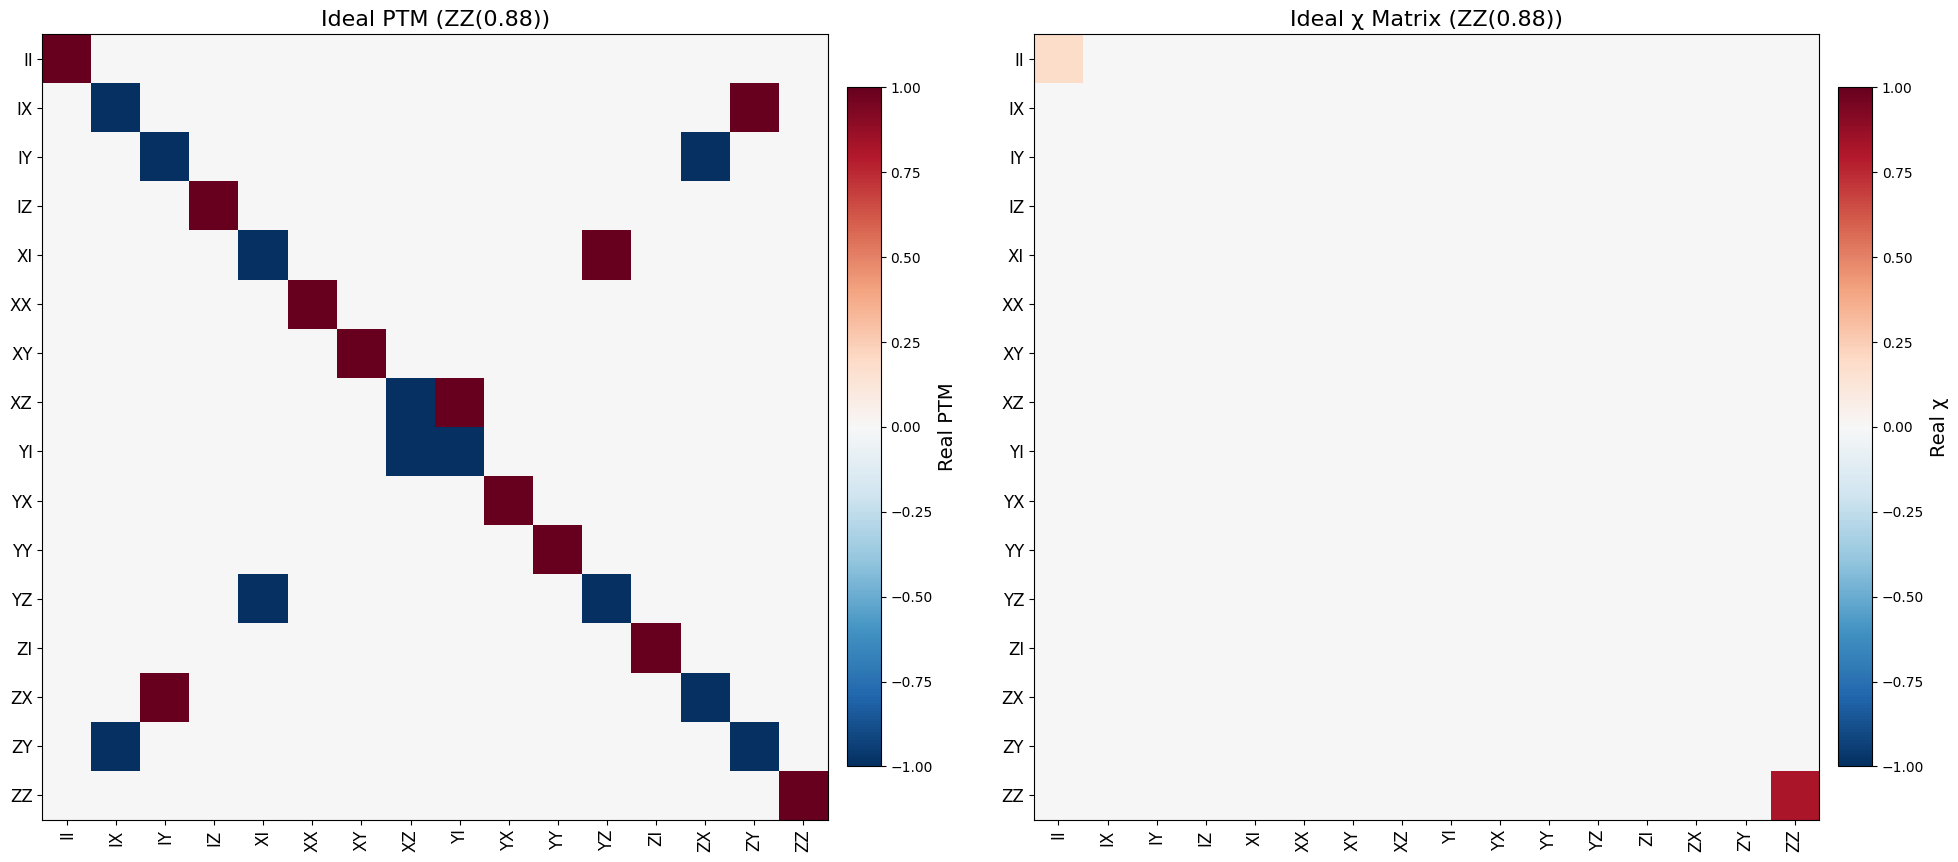

In [15]:
# --- Theta values to sweep over --- #
theta_list = [0, np.pi/2, np.pi/4, np.pi, 2*np.pi, 0.1, 0.44, 0.5, 0.79, 0.88]
# --- Loop and plot --- #
for theta_ZZ in theta_list:
    U_ideal = Qobj(zz_unitary(theta_ZZ))
    ptm_ideal = unitary_to_ptm(U_ideal)
    chi_ideal = qpt(spre(U_ideal) * spost(U_ideal.dag()), op_basis)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
    # PTM plot
    cax1 = ax1.imshow(ptm_ideal.real, cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
    ax1.set_xticks(np.arange(16))
    ax1.set_yticks(np.arange(16))
    ax1.set_xticklabels(ptm_labels, rotation=90, fontsize=12)
    ax1.set_yticklabels(ptm_labels, fontsize=12)
    ax1.set_title(f"Ideal PTM (ZZ({theta_ZZ:.2f}))", fontsize=16)
    # χ matrix plot
    cax2 = ax2.imshow(np.real(chi_ideal), cmap='RdBu_r', norm=Normalize(vmin=-1, vmax=1))
    ax2.set_xticks(np.arange(16))
    ax2.set_yticks(np.arange(16))
    ax2.set_xticklabels(pauli_labels_2q, rotation=90, fontsize=12)
    ax2.set_yticklabels(pauli_labels_2q, fontsize=12)
    ax2.set_title(f"Ideal χ Matrix (ZZ({theta_ZZ:.2f}))", fontsize=16)
    # Colorbars
    fig.colorbar(cax1, ax=ax1, shrink=0.7, pad=0.02).set_label("Real PTM", fontsize=14)
    fig.colorbar(cax2, ax=ax2, shrink=0.7, pad=0.02).set_label("Real χ", fontsize=14)
    plt.tight_layout()
    plt.show()